# Facial Expression Recognition · Individual Extension

## Dataset creation from FER2013 csv and saving them for Training and testing

In [ ]:
import numpy as np
import pandas as pd
import os
from PIL import Image
from sklearn.model_selection import train_test_split

# Change the path to your CSV file
csv_path = 'C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/fer2013.csv'

df = pd.read_csv(csv_path)

# Split the dataframe into training and testing sets
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# Set the main folder paths for training and testing datasets
train_folder_path = 'C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/dataset/train'
test_folder_path = 'C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/dataset/test'

# Create new folders inside the local directory
os.makedirs(train_folder_path, exist_ok=True)
os.makedirs(test_folder_path, exist_ok=True)

# Function to save images for each emotion in separate folders
def save_images(dataframe, folder_path):
    for i, label in enumerate(['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']):
        emotion_df = dataframe[dataframe['emotion'] == i]

        # Create individual folders for each emotion inside the new folder
        emotion_folder_path = os.path.join(folder_path, label)
        os.makedirs(emotion_folder_path, exist_ok=True)

        # Save images for each emotion
        for j, image_pixels in enumerate(emotion_df.iloc[:, 1]):
            image_string = image_pixels.split(' ')
            image_data = np.asarray(image_string, dtype=np.uint8).reshape(48, 48)
            img = Image.fromarray(image_data)

            # Save each image to the respective emotion folder
            img_path = os.path.join(emotion_folder_path, f"{label}_img_{j}.png")
            img.save(img_path, "PNG")

# Save images for training and testing datasets
save_images(train_df, train_folder_path)
save_images(test_df, test_folder_path)


## Loading and Preprocessing the dataset

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image
import scipy

# Load and preprocess the FER-2013 dataset
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    'C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/dataset/train',
    target_size=(48, 48),
    batch_size=32,
    color_mode="grayscale",
    class_mode='sparse',)

test_generator = test_datagen.flow_from_directory(
    'C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/dataset/test',
    target_size=(48, 48),
    batch_size=32,
    color_mode="grayscale",
    class_mode='sparse',
    shuffle=False,)

## Creating Convolution Neural Network for the Emotion Detection

In [4]:
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Conv2D,MaxPooling2D,Dense, Dropout,Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import scipy

# Convolution Neural Network for Emotion Detection.
emotion_model =tf.keras.models.Sequential()

emotion_model.add(Conv2D(32, kernel_size=(3, 3), activation='relu',input_shape=(48,48,1)))
emotion_model.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
emotion_model.add(MaxPooling2D(pool_size=(2,2)))
emotion_model.add(Dropout(0.25))

emotion_model.add(Conv2D(128,kernel_size=(3,3),activation='relu'))
emotion_model.add(MaxPooling2D(pool_size=(2,2)))
emotion_model.add(Conv2D(128, kernel_size=(3,3),activation='relu'))
emotion_model.add(MaxPooling2D(pool_size=(2,2)))
emotion_model.add(Dropout(0.25))

emotion_model.add(Flatten())
emotion_model.add(Dense(1024,activation='relu'))
emotion_model.add(Dropout(0.5))
emotion_model.add(Dense(7,activation='softmax'))

emotion_model.compile(optimizer='adam',
                      loss='sparse_categorical_crossentropy' ,
                      metrics=['accuracy'])

## Training the Convolution Neural Network

In [ ]:
emotion_model_info = emotion_model.fit(
    train_generator,
   steps_per_epoch=28709 // 64,
    epochs=70,
    validation_data=test_generator,  # Use validation_data instead of test_data
    validation_steps=7178 // 64,
)

## Saving the Trained Model

In [ ]:
model_json = emotion_model.to_json()
with open("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/model/emotion_model.json","w") as json_file:
  json_file.write(model_json)
emotion_model.save_weights('C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/model//emotions_model.weights.h5')



## Loading the Model

In [21]:
import cv2
import numpy as np
import json
from keras.models import model_from_json
emotion_dict = {0:'Angry',1:'Disgust',2:'Fear', 3:'Happy', 4:'Neutral',5:'Sad',6:'Surprised'}
# loading json and create model
with open("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/model/emotion_model.json", "r") as json_file:
    loaded_model_json = json.load(json_file)

json_file.close()
emotion_model = model_from_json(json.dumps(loaded_model_json))  # Pass the loaded dictionary as a string to model_from_json

json_file.close()
# load weights into new model
emotion_model.load_weights("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/model/emotions_model.weights.h5")
print("Loaded the model")

emotion_model.compile(optimizer='adam',
                      loss='sparse_categorical_crossentropy' ,
                      metrics=['accuracy'])

Loaded the model


## Emotion Detection On Video on Terminal

In [ ]:
import cv2
from IPython.display import display, Image
import numpy as np

# Define a function to display images in Jupyter Notebook
def cv2_imshow(image):
    _, ret = cv2.imencode('.jpg', image)
    img_str = ret.tobytes()
    display(Image(data=img_str, format='jpg'))

# Start the webcam feed
#cap = cv2.VideoCapture(0)
cap = cv2.VideoCapture('C:/Users/samik/PycharmProjects/Emotion detection/pexels-ron-lach-10295414 (360p).mp4')
while True:
    ret, frame = cap.read()
    frame = cv2.resize(frame, (1280, 720))
    if not ret:
        break
    face_detector = cv2.CascadeClassifier('C:/Users/samik/PycharmProjects/Emotion detection/haarcascade/haarcascade_frontalface_default.xml')
    gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    num_faces = face_detector.detectMultiScale(gray_frame, scaleFactor=1.3, minNeighbors=5)

    for (x, y, w, h) in num_faces:
        cv2.rectangle(frame, (x, y-50), (x+w, y+h+10), (0, 255, 0), 4)
        roi_gray = gray_frame[y:y+h, x:x+w]
        cropped_img = np.expand_dims(np.expand_dims(cv2.resize(roi_gray, (48, 48)), -1), 0)
        emotion_prediction = emotion_model.predict(cropped_img)

        maxindex = int(np.argmax(emotion_prediction))
        cv2.putText(frame, emotion_dict[maxindex], (x+5, y-20), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2, cv2.LINE_AA)

    cv2_imshow(frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()


## Evaluation of the CNN Model

In [26]:
from sklearn.metrics import classification_report,confusion_matrix
import pandas as pd



# Evaluating the model on the test set
test_steps = len(test_generator)
print(test_steps,' ' 'test_steps')
evaluation = emotion_model.evaluate(test_generator, steps=test_steps)

# Get predictions on the test set
predictions = emotion_model.predict(test_generator, steps=test_steps)
predicted_labels = np.argmax(predictions, axis=1)

# Get true labels
true_labels = []

# Iterating over the batches in the test generator to collect true labels
for i in range(test_steps):
    batch_images, batch_labels = test_generator[i]

    # Check if batch_labels is one-dimensional
    if batch_labels.ndim == 1:
        true_labels.extend(batch_labels)
    else:
        true_labels.extend(np.argmax(batch_labels, axis=1))

# Converting class indices to class labels
class_labels = list(test_generator.class_indices.keys())

# Generating a classification report
class_report = classification_report(true_labels, predicted_labels, target_names=class_labels, output_dict=True)

# Printing the evaluation metrics
print("Evaluation Metrics:")
print("Loss:", evaluation[0])
print("Accuracy:", evaluation[1])

# Displaying the classification report as a DataFrame
class_report_df = pd.DataFrame(class_report)
display(class_report_df)

conf_matrix = confusion_matrix(true_labels,predicted_labels)
print("confusion matrix" ,conf_matrix)


225  test_steps
225/225 [==============================] - 8s 37ms/step
Evaluation Metrics:
Loss: 0.47752827405929565
Accuracy: 0.8652828335762024


,Angry,Disgust,Fear,Happy,Neutral,Sad,Surprise,accuracy,macro avg,weighted avg
precision,0.886986,0.977778,0.873016,0.930610,0.784766,0.790824,0.941022,0.865283,0.883572,0.868548
recall,0.788832,0.862745,0.790988,0.942210,0.878717,0.840496,0.903145,0.865283,0.858162,0.865283
f1-score,0.835035,0.916667,0.829980,0.936374,0.829088,0.814904,0.921694,0.865283,0.869106,0.865524
support,985.000000,102.000000,1043.000000,1765.000000,1278.000000,1210.000000,795.000000,0.865283,7178.000000,7178.000000


confusion matrix [[ 777    0   34   17   80   68    9]
 [   7   88    2    0    2    3    0]
 [  30    0  825   23   55   87   23]
 [  11    0   10 1663   46   25   10]
 [  13    0   17   49 1123   75    1]
 [  33    0   31   18  109 1017    2]
 [   5    2   26   17   16   11  718]]


## Video Summarization

In [9]:
import cv2
import numpy as np

# Load the pre-trained emotion detection model and dictionary
# Load the pre-trained emotion detection model and dictionary
# loading json and create model
with open("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/model/emotion_model.json", "r") as json_file:
    loaded_model_json = json.load(json_file)

emotion_model = model_from_json(json.dumps(loaded_model_json))  # Pass the loaded dictionary as a string to model_from_json

# load weights into new model
emotion_model.load_weights("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/model/emotions_model.weights.h5")
print("Loaded the model")

emotion_model.compile(optimizer='adam',
                      loss='sparse_categorical_crossentropy' ,
                      metrics=['accuracy'])

emotion_dict = {0: 'Angry', 1: 'Disgusted', 2: 'Fearful', 3: 'Happy', 4: 'Neutral', 5: 'Sad', 6: 'Surprised'}

# Open the video file
cap = cv2.VideoCapture('C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/Facial_emotion/pexels-ron-lach-10295414 (360p).mp4')
# Assuming you have already loaded the model and defined emotion_dict elsewhere in your code

# Start the webcam feed
#cap = cv2.VideoCapture(0)
cap = cv2.VideoCapture('C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/pexels-ron-lach-10295414 (360p).mp4')

# Define the codec and create a VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*'mp4v')  # Use 'mp4v' codec for MP4 format
out = cv2.VideoWriter('C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/output9.mp4', fourcc, 20.0, (1280, 720))

while True:
    ret, frame = cap.read()
    if not ret:
        break
    frame = cv2.resize(frame, (1280, 720))
    face_detector = cv2.CascadeClassifier('C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/haarcascade_frontalface_default.xml')
    gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    num_faces = face_detector.detectMultiScale(gray_frame, scaleFactor=1.3, minNeighbors=5)

    for (x, y, w, h) in num_faces:
        cv2.rectangle(frame, (x, y-50), (x+w, y+h+10), (0, 255, 0), 4)
        roi_gray = gray_frame[y:y+h, x:x+w]
        cropped_img = np.expand_dims(np.expand_dims(cv2.resize(roi_gray, (48, 48)), -1), 0)
        emotion_prediction = emotion_model.predict(cropped_img)

        maxindex = int(np.argmax(emotion_prediction))
        cv2.putText(frame, emotion_dict[maxindex], (x+5, y-20), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2, cv2.LINE_AA)

    # Write the frame to the output video file
    out.write(frame)

# Release the video capture and writer objects
cap.release()
out.release()
cv2.destroyAllWindows()


Loaded the model
1/1 [==============================] - 0s 29ms/step


## In order to get Emotion Scores

In [8]:
import cv2
import numpy as np
from keras.models import load_model
from sklearn.cluster import KMeans

# Load pre-trained CNN model for facial emotion recognition
# Load the pre-trained CNN model for facial emotion recognition
with open("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/model/emotion_model.json", "r") as json_file:
    loaded_model_json = json.load(json_file)

emotion_model = model_from_json(json.dumps(loaded_model_json))  # Pass the loaded dictionary as a string to model_from_json

# load weights into new model
emotion_model.load_weights("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/model/emotions_model.weights.h5")
print("Loaded the model")  # Replace 'facial_emotion_model.h5' with your model file path

# Function to preprocess an image for input to the CNN model
def preprocess_image(img):
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)  # Convert image to grayscale
    img = cv2.resize(img, (48, 48))  # Resize image to match the input size of the CNN model
    img = img / 255.0  # Normalize pixel values
    img = np.expand_dims(img, axis=-1)  # Add batch dimension
    img = np.expand_dims(img, axis=0)  # Add channel dimension
    return img

# Function to extract emotion scores from an image
def extract_emotion_scores(img):
    img = preprocess_image(img)
    emotion_scores = emotion_model.predict(img)
    return emotion_scores.flatten()

# Open video capture
cap = cv2.VideoCapture('C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/pexels-ron-lach-10295414 (360p).mp4')  # Replace with your video file path

# Initialize variables for emotion scores and frame count
emotion_scores = []
frame_count = 0

# Process video frames
while(cap.isOpened()):
    ret, frame = cap.read()
    if not ret:
        break
    
    # Extract emotion scores from the current frame
    scores = extract_emotion_scores(frame)
    emotion_scores.append(scores)
    
    frame_count += 1

    # Perform clustering on emotion scores periodically (e.g., every N frames)
    if frame_count % 30 == 0:  # Adjust this value as needed
        # Aggregate emotion scores over the window of frames (optional)
        aggregated_scores = np.mean(emotion_scores, axis=0)

        # Calculate the mean of emotion scores across all frames
        mean_emotion_scores = np.mean(emotion_scores, axis=0)
        
        mean_emotion_scores_reshaped = mean_emotion_scores.reshape(-1, 1)

        # Perform K-means clustering on aggregated emotion scores
        num_clusters = 5  # Number of clusters
        kmeans = KMeans(n_clusters=num_clusters)
        kmeans.fit(mean_emotion_scores_reshaped)

        # Get cluster labels for all frames in the window
        cluster_labels = kmeans.predict(mean_emotion_scores_reshaped)

        # Generate video summary based on clustering results (e.g., select key frames)
        # This step depends on your specific summarization criteria

        # Clear emotion scores for the next window
        emotion_scores = []

# Release video capture
cap.release()
cv2.destroyAllWindows()


Loaded the model
1/1 [==============================] - 0s 35ms/step


In [7]:

frame_count = 0
print(emotion_scores)

[array([9.1057399e-04, 2.2983899e-08, 1.1174600e-01, 2.2145391e-03,
       1.0896880e-01, 7.7545267e-01, 7.0740964e-04], dtype=float32), array([9.7735436e-04, 1.5819856e-08, 1.2540115e-01, 1.8547828e-03,
       1.3837995e-01, 7.3226744e-01, 1.1193929e-03], dtype=float32), array([9.6792268e-04, 2.5625404e-08, 1.2095836e-01, 2.3319686e-03,
       1.6900346e-01, 7.0428026e-01, 2.4580222e-03], dtype=float32), array([8.5975911e-04, 1.4378770e-08, 9.7257383e-02, 2.4359701e-03,
       1.8115370e-01, 7.1647424e-01, 1.8188662e-03], dtype=float32), array([1.1678743e-03, 2.1685240e-08, 1.3774417e-01, 3.0070881e-03,
       1.9435202e-01, 6.6035426e-01, 3.3745549e-03], dtype=float32), array([1.9971307e-03, 3.3425206e-08, 2.0166606e-01, 3.3202833e-03,
       1.9732372e-01, 5.9098566e-01, 4.7070910e-03], dtype=float32), array([3.4944331e-03, 6.7255506e-08, 3.1299019e-01, 3.4234247e-03,
       1.5656818e-01, 5.1585263e-01, 7.6711439e-03], dtype=float32), array([5.0696614e-03, 8.3147420e-08, 4.4638300e

## Face Clustering using K-means clustering

## Importing required libraries.

In [9]:
import os
import pickle
import numpy as np
import cv2

from PIL import Image
from imutils import paths, build_montages
from sklearn.cluster import KMeans, DBSCAN
import face_recognition

## Testing Face_clustering

array([[[ 95, 107, 132],
        [ 95, 107, 132],
        [ 95, 107, 132],
        ...,
        [ 37,  50,  66],
        [ 40,  53,  69],
        [ 39,  52,  68]],

       [[ 95, 107, 132],
        [ 95, 107, 132],
        [ 95, 107, 132],
        ...,
        [ 38,  51,  67],
        [ 38,  51,  67],
        [ 37,  50,  66]],

       [[ 96, 108, 133],
        [ 96, 108, 133],
        [ 96, 108, 133],
        ...,
        [ 38,  51,  67],
        [ 38,  51,  67],
        [ 38,  51,  67]],

       ...,

       [[ 94, 119,  47],
        [ 95, 120,  50],
        [ 95, 120,  52],
        ...,
        [ 82, 107,  23],
        [ 82, 107,  23],
        [ 82, 107,  23]],

       [[ 91, 116,  44],
        [ 95, 120,  50],
        [ 99, 123,  56],
        ...,
        [ 83, 106,  23],
        [ 83, 106,  23],
        [ 82, 105,  22]],

       [[ 87, 112,  40],
        [ 96, 121,  51],
        [105, 129,  62],
        ...,
        [ 82, 105,  22],
        [ 82, 105,  22],
        [ 82, 105,  22]]

I found 1 face(s) in this photograph.
A face is located at pixel location Top: 39, Left: 398, Bottom: 101, Right: 460


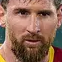

In [10]:
# Path to image
image = face_recognition.load_image_file("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/messi.jpg")
face_locations = face_recognition.face_locations(image)

display(image)

print("I found {} face(s) in this photograph.".format(len(face_locations)))

for face_location in face_locations:

    # Print the location of each face in this image
    top, right, bottom, left = face_location
    print("A face is located at pixel location Top: {}, Left: {}, Bottom: {}, Right: {}".format(top, left, bottom, right))

    # You can access the actual face itself like this:
    face_image = image[top:bottom, left:right]
    pil_image = Image.fromarray(face_image)
    display(pil_image)

## Encoding Creations

In [11]:
# Specify paths
dataset_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset"
encodings_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/encodings.pickle"

# Initialize variables
data = []

# Get image paths from the dataset directory
imagePaths = list(paths.list_images(dataset_path))

# Loop over the image paths
for (i, imagePath) in enumerate(imagePaths):
    print("[INFO] processing image {}/{}".format(i + 1, len(imagePaths)))
    print(imagePath)

    # Read the image
    image = cv2.imread(imagePath)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Detect faces
    boxes = face_recognition.face_locations(image)

    # Compute facial encodings
    encodings = face_recognition.face_encodings(image, boxes)

    # Build dictionary
    d = [{"imagePath": imagePath, "loc": box, "encoding": enc}
         for (box, enc) in zip(boxes, encodings)]
    data.extend(d)

# Save encodings to file
with open(encodings_path, "wb") as f:
    pickle.dump(data, f)

print("Encodings of images saved in {}".format(encodings_path))


[INFO] processing image 1/129
C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset\00000000.jpg
[INFO] processing image 2/129
C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset\00000001.jpg
[INFO] processing image 3/129
C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset\00000002.jpg
[INFO] processing image 4/129
C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset\00000003.jpg
[INFO] processing image 5/129
C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset\00000004.jpg
[INFO] processing image 6/129
C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/Clustering_demo_dataset\00000005.jpg
[INFO] processing image 7/129
C:/Users/samik/OneDrive/Desk

## Using K-means for Clustering

In [12]:
# Specify paths
ENCODINGS_PATH = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/encodings.pickle"
CLUSTERING_RESULT_PATH = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/KNN_Clustering_Result"

# Create Clustering Results directory if it doesn't exist
if not os.path.exists(CLUSTERING_RESULT_PATH):
    os.mkdir(CLUSTERING_RESULT_PATH)

# Load encodings
print("[INFO] loading encodings...")
data = pickle.load(open(ENCODINGS_PATH, "rb"))
data = np.array(data)
encodings = [d["encoding"] for d in data]

# Convert encodings to numpy array
encodings = np.array(encodings)

# Perform KMeans clustering
print("[INFO] clustering...")
kmeans = KMeans(n_clusters=5)  # You can adjust the number of clusters
labels = kmeans.fit_predict(encodings)

# Determine unique label IDs
labelIDs = np.unique(labels)
numUniqueFaces = len(np.where(labelIDs > -1)[0])
print("[INFO] # unique faces: {}".format(numUniqueFaces))

# Loop over unique label IDs
for labelID in labelIDs:
    print("[INFO] faces for cluster: {}".format(labelID))
    idxs = np.where(labels == labelID)[0]
    idxs = np.random.choice(idxs, size=min(25, len(idxs)), replace=False)

    # Initialize list of faces
    faces = []

    # Loop over sampled indexes
    for i in idxs:
        image = cv2.imread(data[i]["imagePath"])
        (top, right, bottom, left) = data[i]["loc"]
        face = image[top:bottom, left:right]

        # Resize face and add to faces list
        face = cv2.resize(face, (96, 96))
        faces.append(face)

    # Create montage
    montage = build_montages(faces, (96, 96), (5, 5))[0]

    # Save the output montage
    title = "Cluster_{}".format(labelID)
    cv2.imwrite(os.path.join(CLUSTERING_RESULT_PATH, title+'.jpg'), montage)

print("Clustering results saved in {}".format(CLUSTERING_RESULT_PATH))

[INFO] loading encodings...
[INFO] clustering...
[INFO] # unique faces: 5
[INFO] faces for cluster: 0
[INFO] faces for cluster: 1
[INFO] faces for cluster: 2
[INFO] faces for cluster: 3
[INFO] faces for cluster: 4
Clustering results saved in C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/KNN_Clustering_Result


## Saving the K-means model

In [13]:
# Save the KMeans model to a file
model_save_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/kmeans_model.pkl"
with open(model_save_path, "wb") as f:
    pickle.dump(kmeans, f)

print(f"KMeans model saved to {model_save_path}")


KMeans model saved to C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/kmeans_model.pkl


## Making predictions with the K-means clustering model

In [14]:
# Load the saved KMeans model
model_load_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/kmeans_model.pkl"
with open(model_load_path, "rb") as f:
    kmeans = pickle.load(f)

def get_face_encoding(image_path):
    # Load the image using face_recognition
    image = face_recognition.load_image_file(image_path)

    # Find the face locations and encodings in the image
    face_locations = face_recognition.face_locations(image)
    face_encodings = face_recognition.face_encodings(image, face_locations)

    if len(face_encodings) > 0:
        return face_encodings[0]  # Return the first face encoding
    else:
        print("No face found in the image.")
        return None

def predict_cluster(image_path, kmeans_model):
    # Get the encoding for the new image
    encoding = get_face_encoding(image_path)

    if encoding is not None:
        # Predict the cluster for the new encoding using the loaded KMeans model
        cluster_label = kmeans_model.predict([encoding])
        return cluster_label[0]
    else:
        return None

# Path to the new image you want to classify
new_image_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/download.jpg"

# Predict the cluster for the new image
cluster_label = predict_cluster(new_image_path, kmeans)

if cluster_label is not None:
    print(f"The new image belongs to cluster: {cluster_label}")
else:
    print("Cluster prediction failed.")


The new image belongs to cluster: 1


## The code that integrates the CNN and K-means results.

In [15]:
import cv2
import numpy as np
import json
from keras.models import model_from_json

# Load the saved KMeans model
model_load_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/kmeans_model.pkl"
with open(model_load_path, "rb") as f:
    kmeans = pickle.load(f)

def get_face_encoding(image_path):
    # Load the image using face_recognition
    image = face_recognition.load_image_file(image_path)

    # Find the face locations and encodings in the image
    face_locations = face_recognition.face_locations(image)
    face_encodings = face_recognition.face_encodings(image, face_locations)

    if len(face_encodings) > 0:
        return face_encodings[0]  # Return the first face encoding
    else:
        print("No face found in the image.")
        return None

def predict_cluster(image_path, kmeans_model):
    # Get the encoding for the new image
    encoding = get_face_encoding(image_path)

    if encoding is not None:
        # Predict the cluster for the new encoding using the loaded KMeans model
        cluster_label = kmeans_model.predict([encoding])
        return cluster_label[0]
    else:
        return None

# Path to the new image you want to classify
new_image_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/download.jpg"

# Predict the cluster for the new image
cluster_label = predict_cluster(new_image_path, kmeans)

if cluster_label is not None:
    print(f"The new image belongs to cluster: {cluster_label}")
else:
    print("Cluster prediction failed.")



# Load the pre-trained emotion detection model and dictionary
with open("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/model/emotion_model.json", "r") as json_file:
    loaded_model_json = json.load(json_file)

emotion_model = model_from_json(json.dumps(loaded_model_json))
emotion_model.load_weights("C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/model/emotions_model.weights.h5")
print("Loaded the model")

emotion_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

emotion_dict = {0: 'Angry', 1: 'Disgusted', 2: 'Fearful', 3: 'Happy', 4: 'Neutral', 5: 'Sad', 6: 'Surprised'}

# Load input image
input_image_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Face_clustering/download.jpg"  # Provide the path to the input image
input_image = cv2.imread(input_image_path)
gray_image = cv2.cvtColor(input_image, cv2.COLOR_BGR2GRAY)

# Detect faces in the image
face_detector = cv2.CascadeClassifier('C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/haarcascade_frontalface_default.xml')
faces = face_detector.detectMultiScale(gray_image, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

# Predict emotions for each detected face and overlay text on the image
for (x, y, w, h) in faces:
    roi_gray = gray_image[y:y+h, x:x+w]
    cropped_img = np.expand_dims(np.expand_dims(cv2.resize(roi_gray, (48, 48)), -1), 0)
    emotion_prediction = emotion_model.predict(cropped_img)
    maxindex = int(np.argmax(emotion_prediction))
    predicted_emotion = emotion_dict[maxindex]
    cv2.putText(input_image, predicted_emotion, (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)

# Save the output image
output_image_path = "C:/Users/samik/OneDrive/Desktop/Machine Learning and Method/Final Project/Facial_emotion/predicted_emotion_image.jpg"  # Provide the desired path for the output image
cv2.imwrite(output_image_path, input_image)

# Store the predicted emotion
predicted_emotion = emotion_dict[maxindex]
print("Predicted emotion:", predicted_emotion)


print(f"The image belongs to {cluster_label} cluster and the predicted emotion is { predicted_emotion}")


Loaded the model
1/1 [==============================] - 0s 145ms/step
Predicted emotion: Happy


## Final Result

In [18]:
print(f"The image belongs to  cluster {cluster_label}  and the predicted emotion is { predicted_emotion}")


The image belongs to  cluster 1  and the predicted emotion is Happy
1
